# RetailPulse - Step 3: Customer Segmentation

Every customer gets a named segment and a suggested action. Two methods are compared: rule-based RFM scores and K-Means
on the same three measures. Outputs: `customer_segments.csv` and `models/kmeans_segments.pkl`.

## 0. Setup

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

ROOT = Path('..')
sys.path.append(str(ROOT))
from src.segmentation import KMEANS_FEATURES, SEGMENT_ACTIONS, SEGMENT_ORDER, rfm_scores, make_kmeans, name_clusters

PROC = ROOT / 'data' / 'processed'
MODELS = ROOT / 'models'; MODELS.mkdir(exist_ok=True)
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)

pd.set_option('display.float_format', '{:,.2f}'.format); pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.figsize': (11, 4.5), 'figure.dpi': 110, 'axes.titleweight': 'bold'})
def save(name): plt.savefig(FIG / f'{name}.png', bbox_inches='tight')
FLOAT = '%.4f'

cust = pd.read_csv(PROC / 'customer_features.csv', index_col='customer_id')
TIERS = ['Bronze', 'Silver', 'Gold', 'Platinum']
SEG_ORDER = SEGMENT_ORDER
print(f'{len(cust):,} customers')
cust[KMEANS_FEATURES].describe().T

10,000 customers


,count,mean,std,min,25%,50%,75%,max
recency_days,"10,000.00",2.85,2.51,1.00,1.00,2.00,4.00,31.00
frequency,"10,000.00",517.46,231.60,255.00,333.00,457.00,680.25,"1,178.00"
monetary,"10,000.00","1,090,290.91","491,029.18","485,805.68","706,582.46","954,782.20","1,410,421.03","2,588,854.88"


## 1. Rule-based RFM scores
Recency, frequency and monetary are each scored 1-5 by quintile and mapped to a segment with simple rules.
Recency is very short for everyone (38% shopped yesterday), so ties are broken by rank and the R score really separates customers by days.

In [2]:
rfm = rfm_scores(cust)
seg = (rfm.groupby('RFM_Segment')
          .agg(customers=('R', 'size'), R=('R', 'mean'), F=('F', 'mean'), M=('M', 'mean'),
               recency_days=('recency_days', 'mean'), frequency=('frequency', 'mean'), monetary=('monetary', 'mean'))
          .sort_values('monetary', ascending=False))
seg['share_%'] = seg['customers'] / len(rfm) * 100
seg

,customers,R,F,M,recency_days,frequency,monetary,share_%
RFM_Segment,,,,,,,,
Champions,1945,4.50,4.60,4.61,1.04,800.74,"1,691,956.27",19.45
Loyal,2229,3.62,3.68,3.67,1.61,571.81,"1,200,917.30",22.29
At Risk,1826,1.60,3.75,3.74,4.37,566.44,"1,193,918.77",18.26
New / Promising,1130,4.49,1.52,1.53,1.08,327.98,"692,066.29",11.30
Needs Attention,696,3.00,1.53,1.53,2.00,328.24,"691,937.54",6.96
Lost / Dormant,2174,1.41,1.48,1.49,5.66,326.23,"686,058.13",21.74


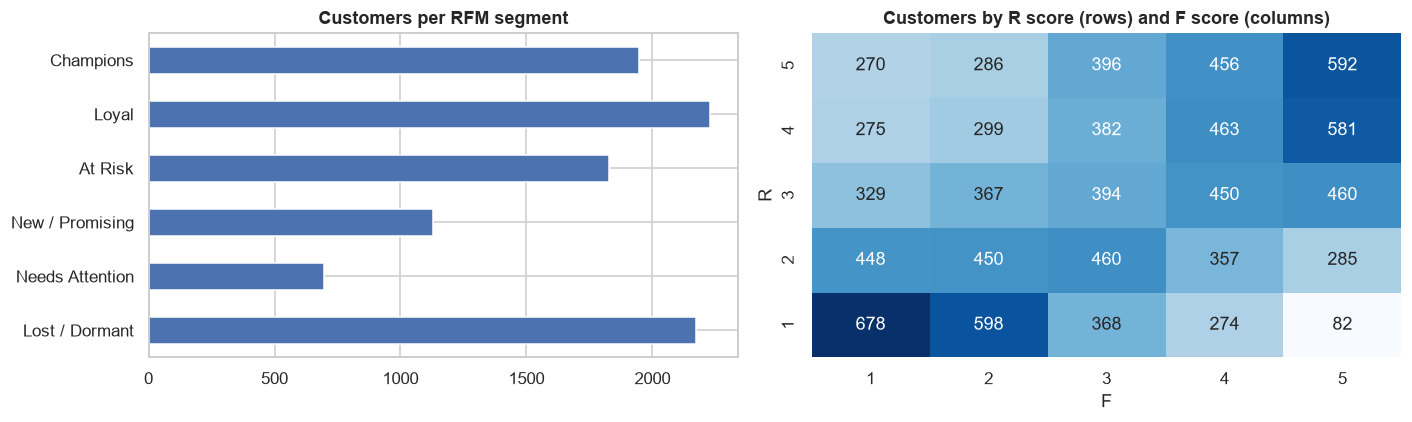

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
seg['customers'].plot.barh(ax=ax[0], color='C0'); ax[0].invert_yaxis(); ax[0].set_title('Customers per RFM segment'); ax[0].set_ylabel('')
sns.heatmap(pd.crosstab(rfm['R'], rfm['F']).sort_index(ascending=False), annot=True, fmt='d', cmap='Blues', ax=ax[1], cbar=False)
ax[1].set_title('Customers by R score (rows) and F score (columns)')
plt.tight_layout(); save('03a_rfm_segments'); plt.show()

- Six fairly even segments (7-22% each); Champions spend ~2.5x the low-frequency groups.
- "Lost / Dormant" (22%) and "At Risk" (18%) sound worse than they are: these customers last shopped 4-6 days ago. The quintiles are relative, and nobody has actually left.
- Frequent shoppers are more likely to have shopped in the last day or two, so R and F are linked.

## 2. Preparing the data for K-Means
R, F and M are skewed, so they're log-transformed and standardised inside a pipeline (`make_kmeans`); the saved model can then score new customers directly.
Frequency and monetary are nearly the same signal, so first a quick check of whether other features give cleaner groups.

In [4]:
from sklearn.cluster import KMeans
def best_silhouette(X, ks=range(3, 7)):
    Xs = StandardScaler().fit_transform(X)
    scores = {k: silhouette_score(Xs, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Xs)) for k in ks}
    k = max(scores, key=scores.get)
    return k, scores[k]

candidates = {
    'R, F, M (log)':                      np.log1p(cust[KMEANS_FEATURES]),
    'R, F (log) + basket value + trend':  pd.concat([np.log1p(cust[['recency_days', 'frequency']]), cust[['aov']],
                                                     cust[['spend_trend_90']].clip(-1, 3)], axis=1),
    'F (log) + basket value + trend':     pd.concat([np.log1p(cust[['frequency']]), cust[['aov']],
                                                     cust[['spend_trend_90']].clip(-1, 3)], axis=1),
}
print('Spearman correlation, frequency vs monetary:', round(cust['frequency'].corr(cust['monetary'], method='spearman'), 3))
pd.DataFrame([(name, *best_silhouette(X)) for name, X in candidates.items()],
             columns=['feature set', 'best k (3-6)', 'silhouette']).set_index('feature set')

Spearman correlation, frequency vs monetary: 0.964


,best k (3-6),silhouette
feature set,,
"R, F, M (log)",6,0.50
"R, F (log) + basket value + trend",5,0.25
F (log) + basket value + trend,4,0.32


Plain log R, F, M gives clearly separated groups (silhouette ~0.45-0.5); adding basket value and spend trend makes it much worse.
So K-Means uses log R, F, M. Frequency effectively counts twice, which is fine because it's the main way customers differ.

## 3. Choosing k
Inertia (elbow) and silhouette for k = 2 to 10.

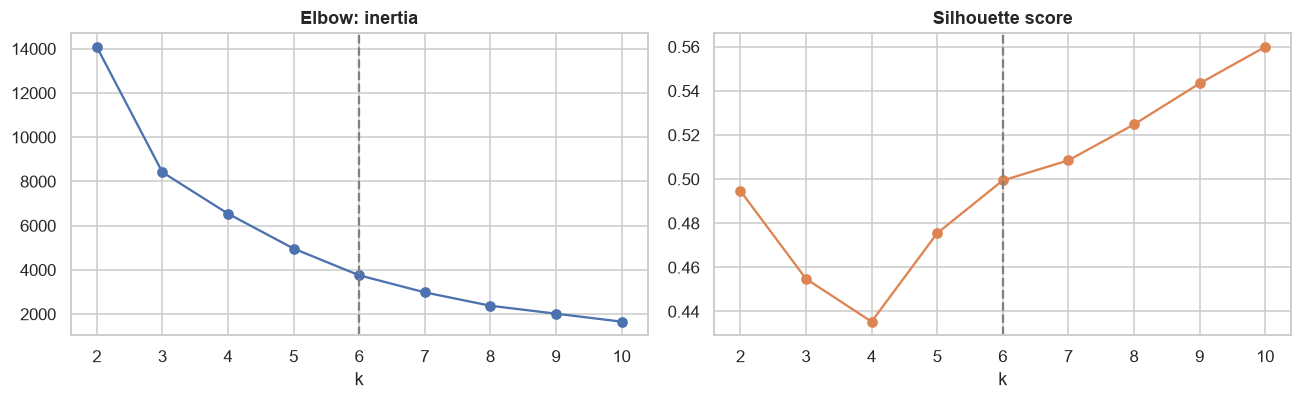

,inertia,silhouette,inertia_drop_%
k,,,
2,"14,085.76",0.49,NaN
3,"8,416.50",0.45,40.25
4,"6,541.94",0.44,22.27
5,"4,964.02",0.48,24.12
6,"3,754.81",0.50,24.36
7,"2,982.79",0.51,20.56
8,"2,377.94",0.52,20.28
9,"2,018.27",0.54,15.13
10,"1,657.63",0.56,17.87


In [5]:
rows = []
for k in range(2, 11):
    pipe = make_kmeans(k).fit(cust[KMEANS_FEATURES])
    Xs = pipe[:-1].transform(cust[KMEANS_FEATURES])
    rows.append({'k': k, 'inertia': pipe[-1].inertia_, 'silhouette': silhouette_score(Xs, pipe[-1].labels_)})
kscores = pd.DataFrame(rows).set_index('k')
kscores['inertia_drop_%'] = -kscores['inertia'].pct_change() * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(kscores.index, kscores['inertia'], 'o-'); ax[0].set_title('Elbow: inertia'); ax[0].set_xlabel('k')
ax[1].plot(kscores.index, kscores['silhouette'], 'o-', color='C1'); ax[1].set_title('Silhouette score'); ax[1].set_xlabel('k')
for a in ax: a.axvline(6, color='grey', ls='--')
plt.tight_layout(); save('03b_choose_k'); plt.show()
kscores

In [6]:
# k=6 vs k=7 profiles
for k in (6, 7):
    lab = make_kmeans(k).fit(cust[KMEANS_FEATURES])[-1].labels_
    p = cust.assign(cluster=lab).groupby('cluster').agg(customers=('frequency', 'size'), recency_days=('recency_days', 'mean'),
                                                        frequency=('frequency', 'mean'), monetary=('monetary', 'mean'))
    display(p.sort_values('frequency', ascending=False).round(1).rename_axis(f'k={k}'))

,customers,recency_days,frequency,monetary
k=6,,,,
3,1020,1.50,"1,072.80","2,261,178.40"
0,1720,1.60,701.20,"1,476,726.20"
5,1376,4.60,496.40,"1,047,268.20"
2,1883,1.40,467.70,"986,480.90"
1,1613,6.80,328.10,"689,049.50"
4,2388,1.80,327.20,"689,496.10"


,customers,recency_days,frequency,monetary
k=7,,,,
5,1020,1.50,"1,072.80","2,261,178.40"
1,1712,1.60,701.30,"1,476,879.90"
4,1348,4.40,498.60,"1,051,800.90"
2,1875,1.40,468.10,"987,104.30"
6,683,9.70,337.50,"707,515.40"
3,1821,1.40,327.40,"690,439.30"
0,1541,4.10,326.60,"687,162.70"


No clear elbow: inertia drops 20-24% per extra cluster. Silhouette dips at k = 4 and then keeps rising, and **k = 6 (0.50)** beats every smaller k.
It goes on rising past 6 only because recency is in whole days, so K-Means can always split a group by a day or two.
The k = 7 table shows exactly that: the extra cluster just splits the infrequent, late shoppers into a 4-day and a 10-day group, which would get the same action.
Six segments is still a manageable number for a marketing team, and it sits inside the 6-8 range the project brief asks for.

## 4. Fitting K-Means (k = 6) and naming the clusters
Cluster numbers change between runs, so `name_clusters` names them from their profile: the two clusters with the longest recency
become **Slipping Away** (longest) and **Cooling Off**, and the other four are named by visit frequency (Champions, Loyal, Regulars, Occasional).

In [7]:
K = 6
km = make_kmeans(K).fit(cust[KMEANS_FEATURES])
names = name_clusters(cust, km[-1].labels_)
rfm['Cluster'] = km[-1].labels_
rfm['Segment'] = pd.Categorical(rfm['Cluster'].map(names), categories=SEG_ORDER, ordered=True)

total_rev = rfm['monetary'].sum()
profile = rfm.groupby('Segment', observed=True).agg(
    customers=('Cluster', 'size'), recency_days=('recency_days', 'mean'), frequency=('frequency', 'mean'),
    monetary=('monetary', 'mean'), aov=('aov', 'mean'), avg_days_between=('avg_days_between', 'mean'),
    overdue_ratio=('overdue_ratio', 'mean'), spend_trend_90=('spend_trend_90', 'mean'), revenue=('monetary', 'sum'))
profile.insert(1, 'share_%', profile['customers'] / len(rfm) * 100)
profile['revenue_share_%'] = profile.pop('revenue') / total_rev * 100
profile

,customers,share_%,recency_days,frequency,monetary,aov,avg_days_between,overdue_ratio,spend_trend_90,revenue_share_%
Segment,,,,,,,,,,
Champions,1020,10.20,1.52,"1,072.80","2,261,178.39","2,107.67",1.36,1.12,0.26,21.15
Loyal,1720,17.20,1.64,701.22,"1,476,726.17","2,106.07",2.08,0.79,0.28,23.30
Regulars,1883,18.83,1.38,467.67,"986,480.92","2,109.49",3.13,0.44,0.34,17.04
Occasional,2388,23.88,1.81,327.19,"689,496.09","2,107.54",4.47,0.41,0.39,15.10
Cooling Off,1376,13.76,4.56,496.38,"1,047,268.24","2,110.71",2.99,1.57,0.26,13.22
Slipping Away,1613,16.13,6.77,328.15,"689,049.46","2,100.44",4.45,1.54,0.31,10.19


In [8]:
mix = pd.crosstab(rfm['Segment'], rfm['loyalty_segment'], normalize='index')[TIERS] * 100
mix.round(1).astype(str) + '%'

loyalty_segment,Bronze,Silver,Gold,Platinum
Segment,,,,
Champions,0.0%,0.0%,0.0%,100.0%
Loyal,0.0%,0.0%,100.0%,0.0%
Regulars,0.6%,99.4%,0.0%,0.0%
Occasional,99.9%,0.1%,0.0%,0.0%
Cooling Off,0.2%,86.3%,13.4%,0.0%
Slipping Away,97.3%,2.7%,0.0%,0.0%


- The four active clusters line up with the loyalty tiers: Champions are all Platinum, Loyal all Gold, Regulars Silver, Occasional Bronze.
- The two late groups are new. **Cooling Off** (14%, mostly Silver) are regular shoppers whose last visit was ~4.6 days ago, about 57% later than their usual gap. **Slipping Away** (16%, almost all Bronze) are infrequent shoppers last seen ~6.8 days ago.
- Basket value is the same in every segment (~PKR 2,100).
- Champions are 10% of customers and 21% of revenue; Champions + Loyal are 27% of customers and 44% of revenue.
- Neither late group is spending less over 90 days yet (+26% and +31%). Step 4 checks whether being late predicts a real drop.

## 5. Checking the segments

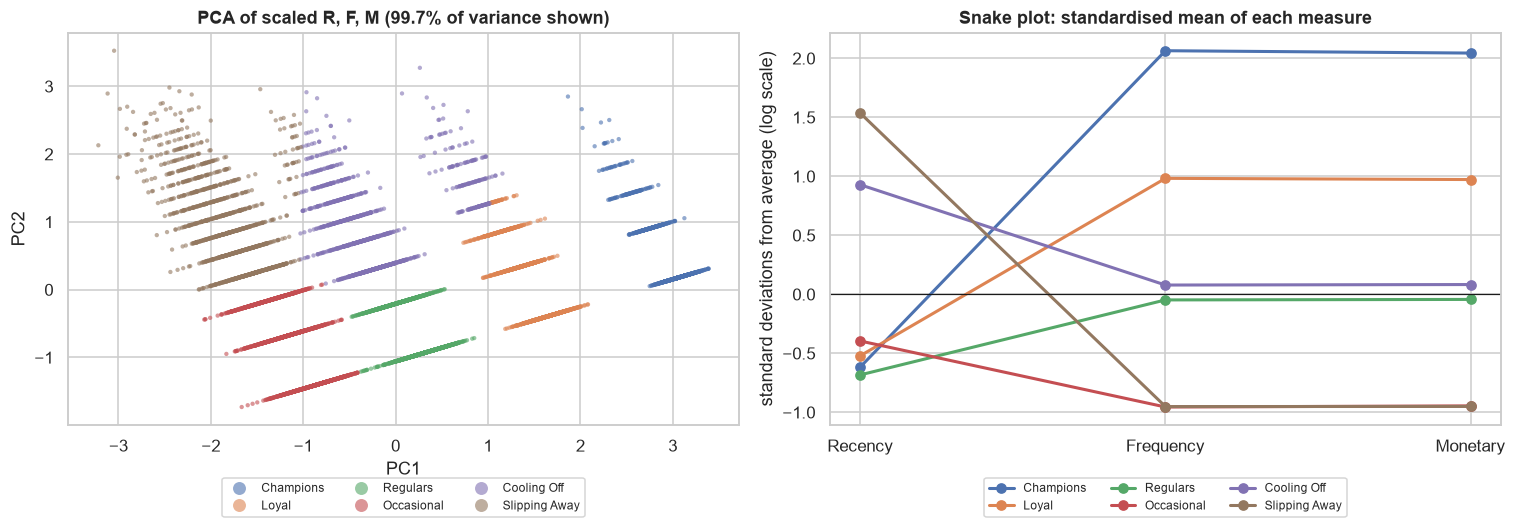

In [9]:
Xs = km[:-1].transform(cust[KMEANS_FEATURES])
pcs = PCA(n_components=2, random_state=42).fit(Xs)
pts = pcs.transform(Xs)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=pts[:, 0], y=pts[:, 1], hue=rfm['Segment'], hue_order=SEG_ORDER, s=8, alpha=.6, ax=ax[0], linewidth=0)
ax[0].set_title(f'PCA of scaled R, F, M ({pcs.explained_variance_ratio_.sum():.1%} of variance shown)')
ax[0].set_xlabel('PC1'); ax[0].set_ylabel('PC2'); ax[0].legend(markerscale=3, title='', loc='upper center', bbox_to_anchor=(.5, -.12), ncol=3, fontsize=8)

snake = pd.DataFrame(Xs, columns=['Recency', 'Frequency', 'Monetary'], index=rfm.index).groupby(rfm['Segment'], observed=True).mean()
for s in SEG_ORDER: ax[1].plot(snake.columns, snake.loc[s], 'o-', label=s, lw=2)
ax[1].axhline(0, color='k', lw=.8); ax[1].set_title('Snake plot: standardised mean of each measure')
ax[1].set_ylabel('standard deviations from average (log scale)')
ax[1].legend(title='', loc='upper center', bbox_to_anchor=(.5, -.12), ncol=3, fontsize=8)
plt.tight_layout(); save('03c_segments_pca_snake'); plt.show()

Cross-check against the rule-based RFM segments.

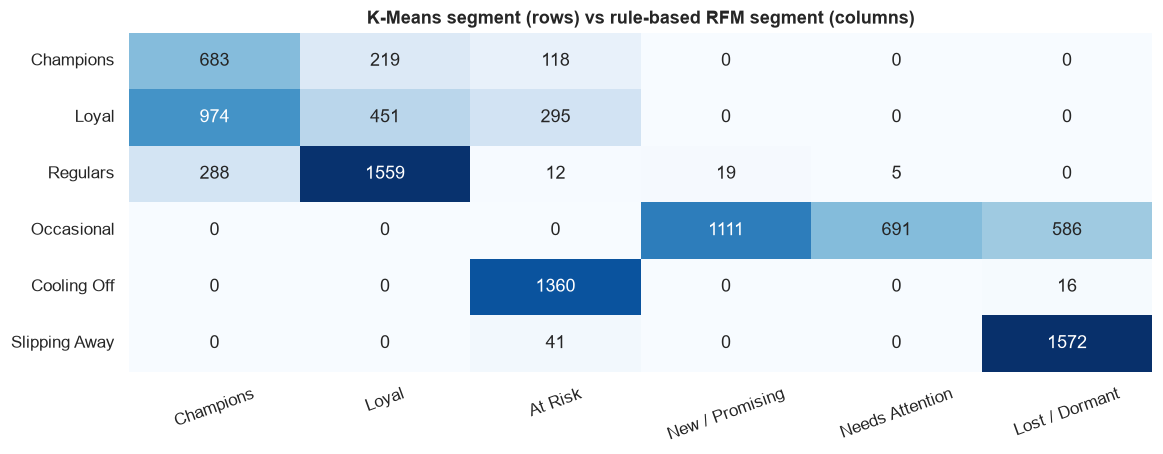

In [10]:
ct = pd.crosstab(rfm['Segment'], rfm['RFM_Segment'])
ct = ct[seg.index]                                     # RFM segments ordered by spend
fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
ax.set_title('K-Means segment (rows) vs rule-based RFM segment (columns)'); ax.set_xlabel(''); ax.set_ylabel('')
plt.xticks(rotation=20); save('03d_kmeans_vs_rfm'); plt.show()

Stability across random seeds and against a different algorithm, measured with the adjusted Rand index (1 = identical, 0 = random).

In [11]:
seeds = [make_kmeans(K, random_state=s).fit(cust[KMEANS_FEATURES])[-1].labels_ for s in range(5)]
seed_ari = [adjusted_rand_score(seeds[0], s) for s in seeds[1:]]

sample = rfm.sample(4000, random_state=42).index
pos = rfm.index.get_indexer(sample)
agg = AgglomerativeClustering(n_clusters=K, linkage='ward').fit_predict(Xs[pos])
pd.DataFrame({
    'check': ['K-Means with 4 other random seeds (min ARI)', 'Agglomerative (Ward) vs K-Means, 4,000-customer sample',
              'K-Means vs rule-based RFM segments', 'K-Means vs loyalty tier'],
    'ARI': [min(seed_ari), adjusted_rand_score(rfm['Cluster'].iloc[pos], agg),
            adjusted_rand_score(rfm['Segment'], rfm['RFM_Segment']), adjusted_rand_score(rfm['Segment'], rfm['loyalty_segment'])],
}).set_index('check')

,ARI
check,
K-Means with 4 other random seeds (min ARI),1.00
"Agglomerative (Ward) vs K-Means, 4,000-customer sample",0.88
K-Means vs rule-based RFM segments,0.50
K-Means vs loyalty tier,0.63


- Very stable across seeds (ARI 1.00). Ward clustering finds broadly the same groups (0.88); K-Means is kept because it can `predict` new customers.
- PCA shows nearly all the variance in 2 dimensions since F and M are almost the same. The stripes come from recency being whole days.
- Agreement with RFM is 0.50, up from 0.36 with five segments. Cooling Off maps almost entirely to RFM's "At Risk" and Slipping Away to "Lost / Dormant"; the differences are mostly among frequent shoppers, where RFM splits on small recency gaps.
- K-Means is used as the main segmentation; RFM scores are kept as extra columns.

## 6. Business actions and outputs

In [12]:
actions = pd.DataFrame([(s, *SEGMENT_ACTIONS[s]) for s in SEG_ORDER], columns=['Segment', 'Who they are', 'Recommended action']).set_index('Segment')
actions = actions.join(profile[['customers', 'share_%', 'revenue_share_%']])
actions

,Who they are,Recommended action,customers,share_%,revenue_share_%
Segment,,,,,
Champions,"Shop almost daily, highest spend","VIP perks, early access to new products, refer...",1020,10.20,21.15
Loyal,"Shop every 2 days, high spend",Bundles and cross-sell to move them up to Cham...,1720,17.20,23.30
Regulars,"Shop every 3 days, mid spend",Personalised offers in categories they already...,1883,18.83,17.04
Occasional,"Shop every 4-5 days, lowest spend",Visit-frequency incentives (e.g. points for a ...,2388,23.88,15.10
Cooling Off,Regular shoppers who are a few days late,Friendly reminder with a personalised offer,1376,13.76,13.22
Slipping Away,"Infrequent shoppers, longest since last visit","Win-back message with a small, time-limited offer",1613,16.13,10.19


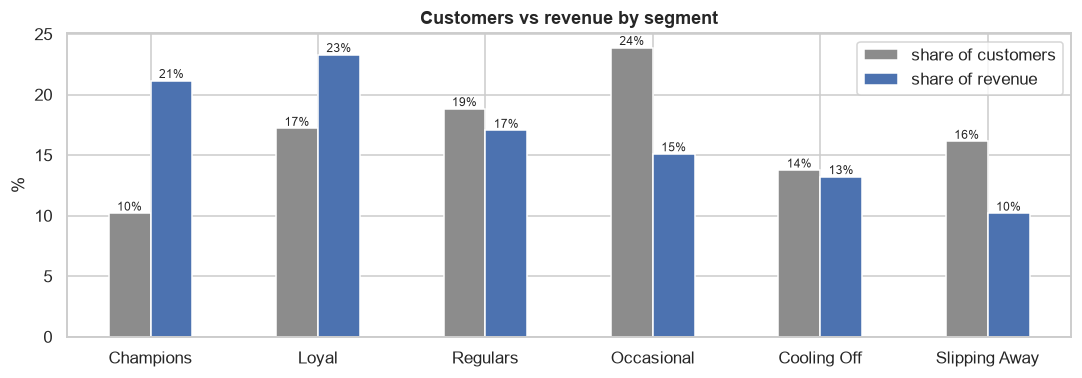

In [13]:
fig, ax = plt.subplots(figsize=(10, 3.6))
share = profile[['share_%', 'revenue_share_%']].rename(columns={'share_%': 'share of customers', 'revenue_share_%': 'share of revenue'})
share.plot.bar(ax=ax, rot=0, color=['C7', 'C0'])
ax.set_ylabel('%'); ax.set_xlabel(''); ax.set_title('Customers vs revenue by segment')
for c in ax.containers: ax.bar_label(c, fmt='%.0f%%', fontsize=8)
plt.tight_layout(); save('03e_segment_value'); plt.show()

In [14]:
keep = ['recency_days', 'frequency', 'monetary', 'aov', 'avg_days_between', 'overdue_ratio', 'spend_trend_90',
        'loyalty_segment', 'preferred_channel', 'city', 'R', 'F', 'M', 'RFM_Score', 'RFM_Segment', 'Cluster', 'Segment']
rfm[keep].to_csv(PROC / 'customer_segments.csv', index_label='customer_id', float_format=FLOAT)
joblib.dump({'model': km, 'features': KMEANS_FEATURES, 'names': names}, MODELS / 'kmeans_segments.pkl')

# reload check
saved = joblib.load(MODELS / 'kmeans_segments.pkl')
again = pd.Series(saved['model'].predict(cust[saved['features']]), index=cust.index).map(saved['names'])
assert (again == rfm['Segment'].astype(str)).all()
print('saved customer_segments.csv', rfm[keep].shape, 'and models/kmeans_segments.pkl (pipeline + feature list + names)')

saved customer_segments.csv (10000, 17) and models/kmeans_segments.pkl (pipeline + feature list + names)


Every customer now has one of six K-Means segments plus RFM scores (`customer_segments.csv`), k = 6 is backed by the silhouette
and k = 7 checks, and the model is saved with its feature list and names (a reload check confirms it).
Step 4 reports churn by segment; the dashboard uses `SEGMENT_ACTIONS` for the action text.